# Logistic Regression with scikit-learn


This notebook focuses on the **workflow** for implementing logistic regression with scikit-learn. You will see that the problem at hand can be solved perfectly with logistic regression. 

By the end of this notebook, you should know what steps to take in sequence to implement a model with scikit-learn and be able to apply it to unseen data.


## Data

To start with a simple example, let’s say that your goal is to build a logistic regression model in Python in order to determine whether candidates would get admitted to a prestigious university.

Here, there are two possible outcomes: Admitted (represented by the value of ‘1’) vs. Rejected (represented by the value of ‘0’).

You can then build a logistic regression in Python, where:

The dependent variable represents whether a person gets admitted and the 3 independent variables are the GMAT score, GPA and Years of work experience.

In [1]:
# Import libraries
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score

In [2]:
# Generating the data
candidates = {
    "gmat": [
        780, 750, 690, 710, 680, 730, 690, 720, 740, 690,
        610, 690, 710, 680, 770, 610, 580, 650, 540, 590,
        620, 600, 550, 550, 570, 670, 660, 580, 650, 660,
        640, 620, 660, 660, 680, 650, 670, 580, 590, 690,
    ],
    "gpa": [
        4, 3.9, 3.3, 3.7, 3.9, 3.7, 2.3, 3.3, 3.3, 1.7,
        2.7, 3.7, 3.7, 3.3, 3.3, 3, 2.7, 3.7, 2.7, 2.3,
        3.3, 2, 2.3, 2.7, 3, 3.3, 3.7, 2.3, 3.7, 3.3,
        3, 2.7, 4, 3.3, 3.3, 2.3, 2.7, 3.3, 1.7, 3.7,
    ],
    "work_experience": [
        3, 4, 3, 5, 4, 6, 1, 4, 5, 1,
        3, 5, 6, 4, 3, 1, 4, 6, 2, 3,
        2, 1, 4, 1, 2, 6, 4, 2, 6, 5,
        1, 2, 4, 6, 5, 1, 2, 1, 4, 5,
    ],
    "admitted": [
        1, 1, 1, 1, 1, 1, 0, 1, 1, 0,
        0, 1, 1, 1, 1, 0, 0, 1, 0, 0,
        0, 0, 0, 0, 0, 1, 1, 0, 1, 1,
        0, 0, 1, 1, 1, 0, 0, 0, 0, 1,
    ],
}

df = pd.DataFrame(
    candidates, columns=pd.Index(["gmat", "gpa", "work_experience", "admitted"])
)
df.head()

,gmat,gpa,work_experience,admitted
0,780,4.0,3,1
1,750,3.9,4,1
2,690,3.3,3,1
3,710,3.7,5,1
4,680,3.9,4,1


In [3]:
# Defining target and predictors
X = df[["gmat", "gpa", "work_experience"]]
y = df["admitted"]

In [4]:
# Train-test-split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=0
)

## Create Logistic Regression

In [5]:
# Modelling
lr = LogisticRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)

### Confusion Matrix

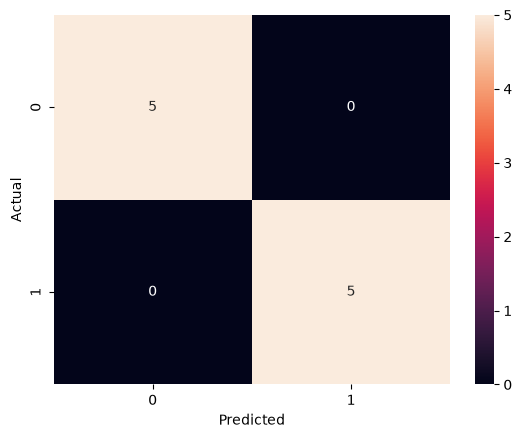

In [6]:
# Confusion matrix using pandas crosstab
conf_matrix = pd.crosstab(y_test, y_pred, rownames=["Actual"], colnames=["Predicted"])
sns.heatmap(conf_matrix, annot=True);

In [7]:
print("Accuracy: ", accuracy_score(y_test, y_pred))

Accuracy:  1.0


In [8]:
confusion_matrix(y_test, y_pred)

array([[5, 0],
       [0, 5]])

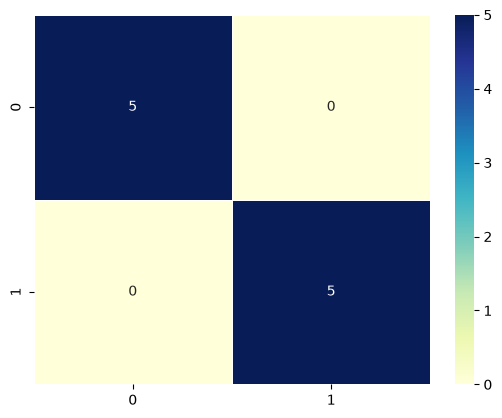

In [9]:
# Confusion matrix using the confusion_matrix function from sklearn
cfm = confusion_matrix(y_test, y_pred)
sns.heatmap(cfm, cmap="YlGnBu", annot=True, fmt="d", linewidths=0.5);

**Check your understanding**

- Check out the Scikit-Learn documentation for logistic regression and find out how to output the estimated parameters of your model.

<details>
<summary>Show answer</summary>

After fitting, the learned parameters live on the model object: `lr.coef_` holds the weight for each feature and `lr.intercept_` holds the bias term. These are the b1 and b0 of the logistic model. You can print them directly once the model is fit, for example `print(lr.coef_, lr.intercept_)`.
</details>

- Scikit-Learn usually has pretty good default values set for the hyperparameters of models. Try printing out all the defined hyperparameters of your model and check what these hyperparameters mean and what other options would be available for these hyperparameters.

<details>
<summary>Show answer</summary>

Call `lr.get_params()` to see every hyperparameter and its current value. The key ones for logistic regression are `C` (inverse of regularisation strength, where a smaller value means stronger regularisation), `penalty` (the type of regularisation, such as l2), `solver` (the optimisation algorithm), and `max_iter` (how many iterations the solver may run). The scikit-learn documentation lists the allowed options for each.
</details>

- Try to change the threshold to 0.3 and print out the confusion matrix for this threshold. 

<details><summary>
Click here for a hint for the last task
</summary>
You need to output the predicted probabilities of your model and use a function that gives you a value of 0 if the predicted probability is less than/equal to 0.3 and 1 if it is above the threshold. Now you can use this array as y_pred to print the confusion matrix.
</details>

<details>
<summary>Show answer</summary>

`predict()` always uses a fixed 0.5 cut-off, so to use a different threshold you work from the predicted probabilities instead. Get them with `lr.predict_proba(X_test)[:, 1]` (the probability of class 1), apply your own cut-off, then pass the result to `confusion_matrix`:

```python
proba = lr.predict_proba(X_test)[:, 1]
y_pred = (proba > 0.3).astype(int)
confusion_matrix(y_test, y_pred)
```

Lowering the threshold to 0.3 labels more points as class 1, which usually raises recall (fewer false negatives) at the cost of more false positives.
</details>
